# 01 — IEEE-CIS Exploratory Data Analysis

Visual companion to the canonical, script-generated reports:

- `python -m src.data.eda` → `reports/eda_metrics.json` (summarised in `reports/eda_summary.md`)
- `python -m src.data.quality` → `reports/data_quality.{json,md}`

**Re-run from a clean kernel** (repo root, venv with `requirements-eda.txt`):

```
.venv\Scripts\jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda.ipynb
```

Figures are written to `reports/figures/`. The notebook shows aggregates only and never displays
raw rows. The last cell asserts that its metrics equal `reports/eda_metrics.json`. Needs about
5 GB of RAM because all 435 merged columns are loaded.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data.eda import column_family, compute_eda_metrics
from src.data.load import HAS_IDENTITY, KEY, LABEL, IEEECISPaths, load_identity, load_ieee_cis
from src.data.quality import peak_memory_mb

REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
LEGIT, FRAUD = "#4C72B0", "#C44E52"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
STARTED = time.perf_counter()


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=110)
    plt.show()
    print("saved", f"reports/figures/{name}")

## 1. Load and merge integrity

Identity is left-joined onto transactions on `TransactionID`. Every transaction must survive the join, and every identity row should match a transaction.

In [2]:
df = load_ieee_cis()  # validates schema, labels and unique keys; left-joins identity
identity_rows = len(load_identity(IEEECISPaths.from_dir().identity))
matched = int(df[HAS_IDENTITY].sum())
integrity = {
    "merged_rows": len(df),
    "merged_columns": df.shape[1],
    "transaction_ids_unique": bool(df[KEY].is_unique),
    "identity_rows": identity_rows,
    "identity_rows_matched": matched,
    "identity_rows_orphaned": identity_rows - matched,
    "transaction_dt_sorted": bool(df["TransactionDT"].is_monotonic_increasing),
    "memory_mb": round(df.memory_usage(deep=True).sum() / 1e6, 1),
}
committed = json.loads((REPORTS / "eda_metrics.json").read_text(encoding="utf-8"))["merge_integrity"]
assert integrity["merged_rows"] == committed["transaction_rows"]  # left join kept every transaction
assert integrity["identity_rows"] == committed["identity_rows"]
assert integrity["identity_rows_orphaned"] == committed["identity_rows_orphaned"]
assert integrity["transaction_ids_unique"]
integrity

{'merged_rows': 590540,
 'merged_columns': 435,
 'transaction_ids_unique': True,
 'identity_rows': 144233,
 'identity_rows_matched': 144233,
 'identity_rows_orphaned': 0,
 'transaction_dt_sorted': True,
 'memory_mb': 1536.2}

## 2. Class imbalance

{'legit': 569877, 'fraud': 20663, 'fraud_rate': 0.03499}


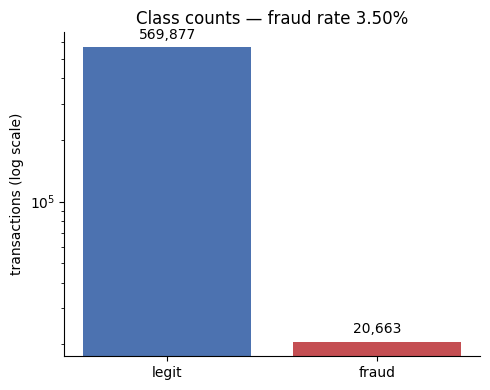

saved reports/figures/class_balance.png


In [3]:
counts = df[LABEL].value_counts().sort_index()
print({"legit": int(counts[0]), "fraud": int(counts[1]), "fraud_rate": round(float(df[LABEL].mean()), 5)})

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["legit", "fraud"], counts.to_numpy(), color=[LEGIT, FRAUD])
ax.set_yscale("log")
ax.set_ylabel("transactions (log scale)")
ax.set_title(f"Class counts — fraud rate {df[LABEL].mean():.2%}")
for i, v in enumerate(counts.to_numpy()):
    ax.text(i, v * 1.1, f"{v:,}", ha="center")
save(fig, "class_balance.png")

## 3. Transaction amount

Share of each class's transactions per amount bin (log-spaced bins), so the two classes are comparable despite the 27:1 imbalance.

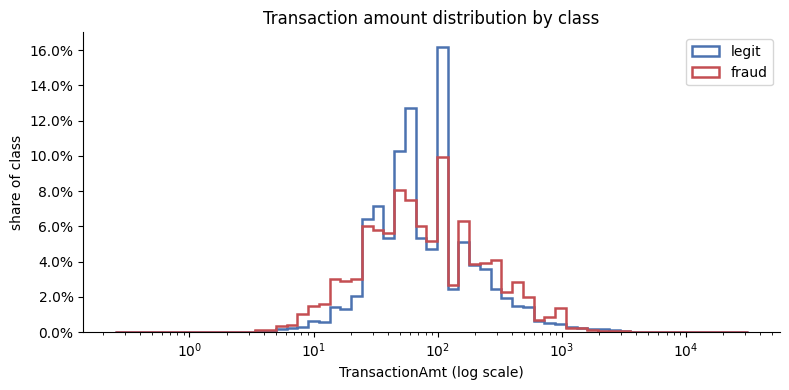

saved reports/figures/amount_distribution.png


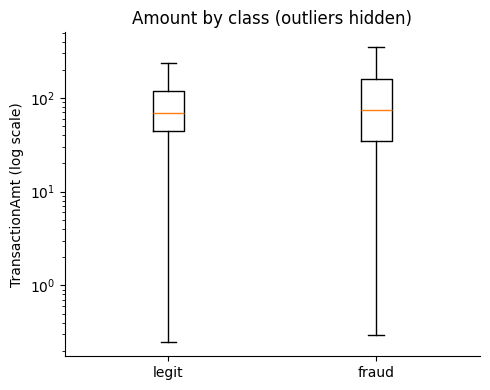

saved reports/figures/amount_by_class.png


,count,mean,std,min,50%,95%,99%,max
isFraud,,,,,,,,
0,569877.0,134.51,239.40,0.25,68.5,435.0,1104.0,31937.39
1,20663.0,149.24,232.21,0.29,75.0,500.0,994.0,5191.00


In [4]:
amt = df["TransactionAmt"]
bins = np.logspace(np.log10(max(amt.min(), 0.1)), np.log10(amt.max()), 60)
fig, ax = plt.subplots(figsize=(8, 4))
for label, name, color in ((0, "legit", LEGIT), (1, "fraud", FRAUD)):
    values = amt[df[LABEL] == label]
    ax.hist(values, bins=bins, weights=np.full(len(values), 1 / len(values)),
            histtype="step", lw=1.8, color=color, label=name)
ax.set_xscale("log")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("TransactionAmt (log scale)")
ax.set_ylabel("share of class")
ax.set_title("Transaction amount distribution by class")
ax.legend()
save(fig, "amount_distribution.png")

fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([amt[df[LABEL] == 0], amt[df[LABEL] == 1]], showfliers=False)
ax.set_xticks([1, 2], ["legit", "fraud"])
ax.set_yscale("log")
ax.set_ylabel("TransactionAmt (log scale)")
ax.set_title("Amount by class (outliers hidden)")
save(fig, "amount_by_class.png")
df.groupby(LABEL)["TransactionAmt"].describe(percentiles=[0.5, 0.95, 0.99]).round(2)

## 4. Fraud over time

`TransactionDT` is a seconds offset from an undisclosed reference point, so days are relative, not calendar dates.

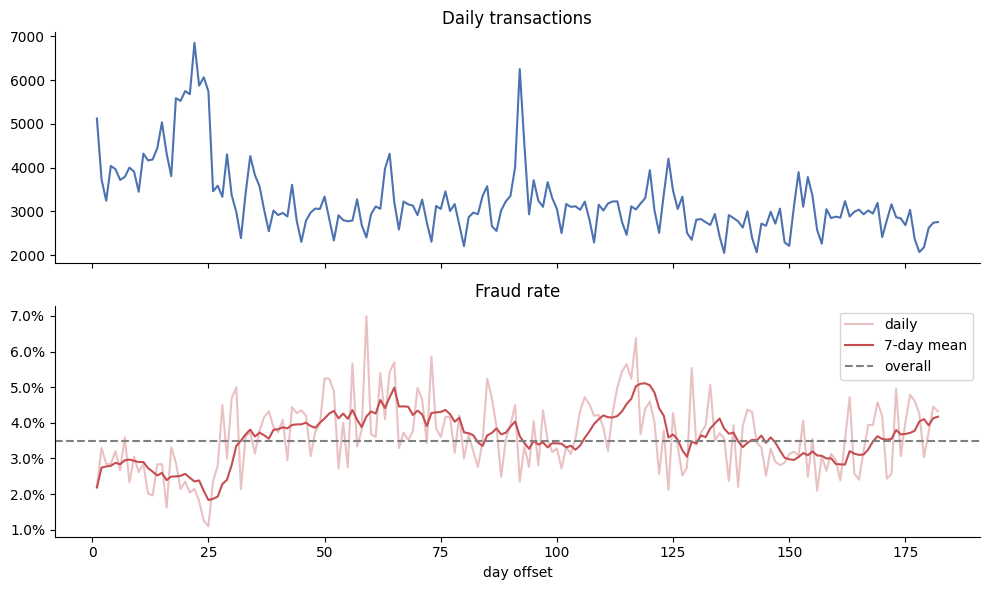

saved reports/figures/fraud_over_time.png


,rows,fraud_rate
block_30d,,
0,134339,0.02532
1,89399,0.04001
2,92189,0.04040
3,98615,0.03953
4,83571,0.03410
5,86934,0.03419
6,5493,0.04387


In [5]:
day = (df["TransactionDT"] // 86400).astype(int).rename("day")
daily = df.groupby(day)[LABEL].agg(transactions="size", fraud_rate="mean")
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(daily.index, daily["transactions"], color=LEGIT)
axes[0].set_title("Daily transactions")
axes[1].plot(daily.index, daily["fraud_rate"], color=FRAUD, alpha=0.35, label="daily")
axes[1].plot(daily.index, daily["fraud_rate"].rolling(7, min_periods=1).mean(), color=FRAUD,
             label="7-day mean")
axes[1].axhline(df[LABEL].mean(), ls="--", color="grey", label="overall")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_title("Fraud rate")
axes[1].set_xlabel("day offset")
axes[1].legend()
save(fig, "fraud_over_time.png")
block = ((day - day.min()) // 30).rename("block_30d")
df.groupby(block)[LABEL].agg(rows="size", fraud_rate="mean").round(5)

## 5. Missingness

Families use the same grouping as `src.data.eda.column_family` (`V123` → `V`, `id_05` → `id`).

columns >50% missing: 214 | >90%: 12
D family mean missing (unrounded): 0.581513


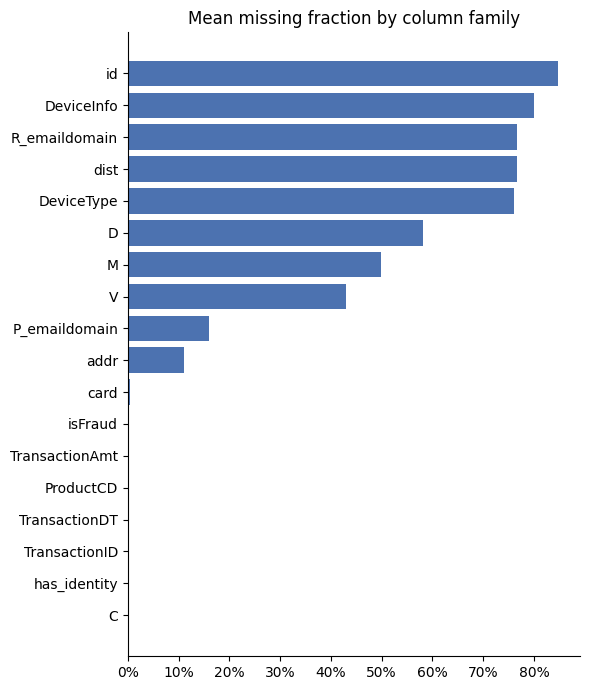

saved reports/figures/missingness.png


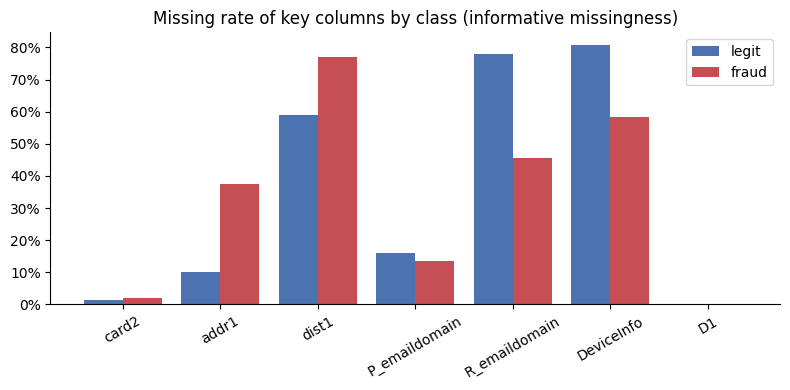

saved reports/figures/missingness_by_class.png


isFraud,legit,fraud
card2,0.0149,0.0205
addr1,0.1017,0.3746
dist1,0.5902,0.7699
P_emaildomain,0.1609,0.1350
R_emaildomain,0.7788,0.4567
DeviceInfo,0.8069,0.5835
D1,0.0021,0.0022


In [6]:
missing = df.isna().mean()
family = missing.groupby(column_family).mean().sort_values()
print("columns >50% missing:", int((missing > 0.5).sum()), "| >90%:", int((missing > 0.9).sum()))
print("D family mean missing (unrounded):", round(float(family["D"]), 6))

fig, ax = plt.subplots(figsize=(6, 7))
ax.barh(family.index, family.to_numpy(), color=LEGIT)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Mean missing fraction by column family")
save(fig, "missingness.png")

key_cols = ["card2", "addr1", "dist1", "P_emaildomain", "R_emaildomain", "DeviceInfo", "D1"]
by_class = df[key_cols].isna().groupby(df[LABEL]).mean().T.rename(columns={0: "legit", 1: "fraud"})
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(key_cols))
ax.bar(x - 0.2, by_class["legit"], 0.4, color=LEGIT, label="legit")
ax.bar(x + 0.2, by_class["fraud"], 0.4, color=FRAUD, label="fraud")
ax.set_xticks(x, key_cols, rotation=30)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Missing rate of key columns by class (informative missingness)")
ax.legend()
save(fig, "missingness_by_class.png")
by_class.round(4)

## 6. Categorical comparisons

Fraud rate per category, with group sizes in the labels. Missing values form their own `(missing)` group. For `P_emaildomain`, only the 10 highest-volume domains are shown. Small groups are noisy, so read rates together with `n`.

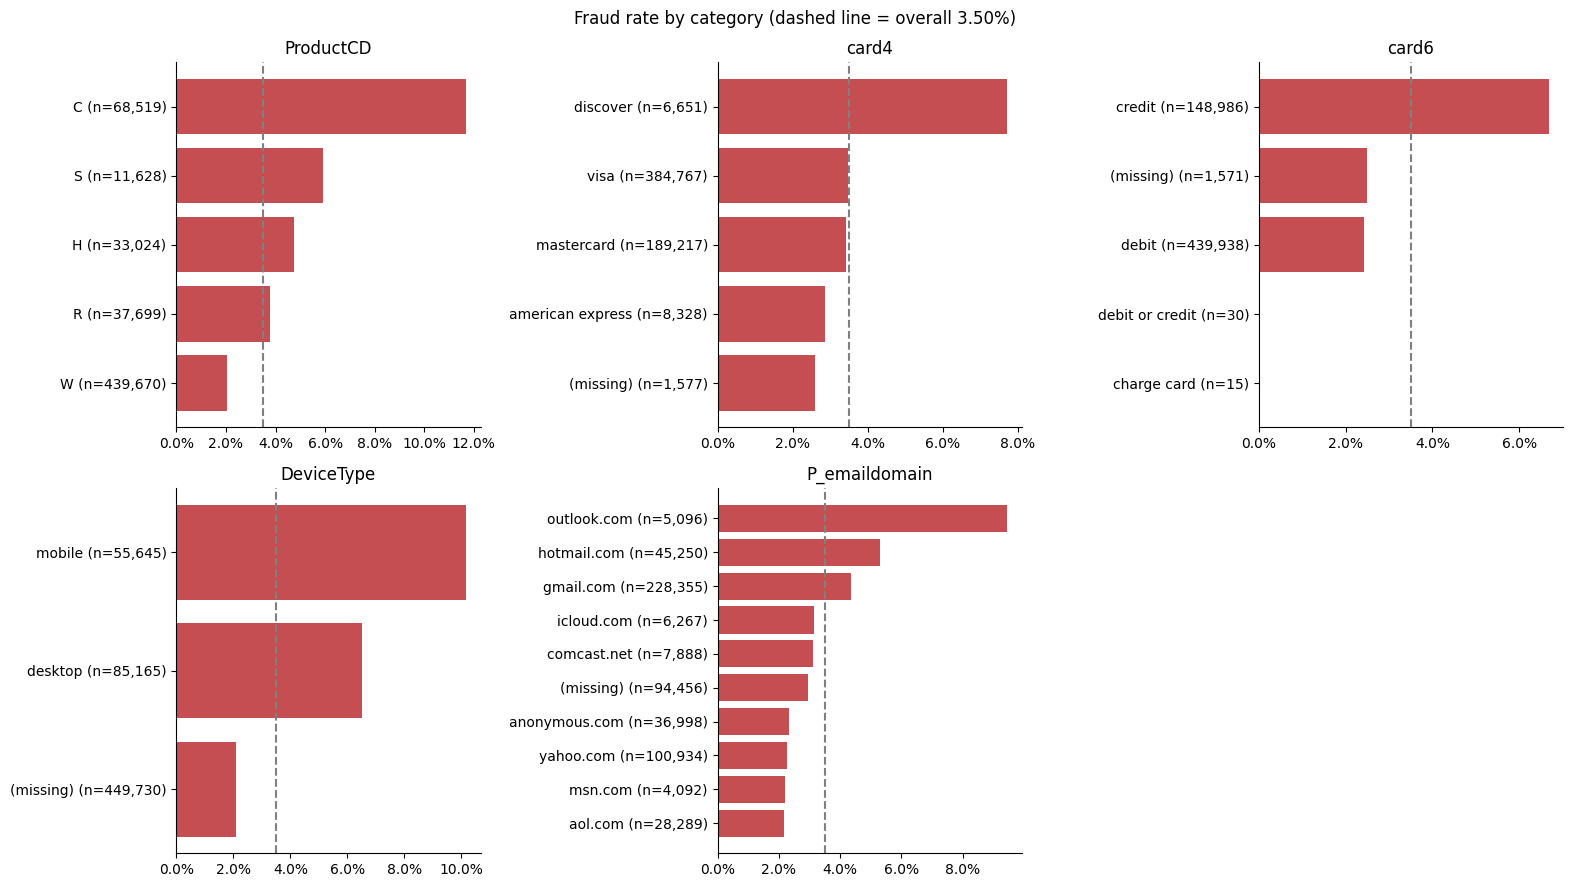

saved reports/figures/categorical_fraud_rates.png


n  fraud_rate
column        value                               
ProductCD     W                 439670      0.0204
              R                  37699      0.0378
              H                  33024      0.0477
              S                  11628      0.0590
              C                  68519      0.1169
card4         (missing)           1577      0.0260
              american express    8328      0.0287
              mastercard        189217      0.0343
              visa              384767      0.0348
              discover            6651      0.0773
card6         charge card           15      0.0000
              debit or credit       30      0.0000
              debit             439938      0.0243
              (missing)           1571      0.0248
              credit            148986      0.0668
DeviceType    (missing)         449730      0.0210
              desktop            85165      0.0652
              mobile             55645      0.1017
P_emaildomain aol.com            28289      0.0218
              msn.com             4092      0.0220
              yahoo.com         100934      0.0228
              anonymous.com      36998      0.0232
              (missing)          94456      0.0295
              comcast.net         7888      0.0312
              icloud.com          6267      0.0314
              gmail.com         228355      0.0435
              hotmail.com        45250      0.0530
              outlook.com         5096      0.0946

In [7]:
cats = ["ProductCD", "card4", "card6", "DeviceType", "P_emaildomain"]
overall = df[LABEL].mean()
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
tables = {}
for ax, col in zip(axes.flat, cats):
    groups = df[col].astype(object).fillna("(missing)")
    g = df.groupby(groups)[LABEL].agg(n="size", fraud_rate="mean")
    if col == "P_emaildomain":
        g = g.nlargest(10, "n")
    g = g.sort_values("fraud_rate")
    tables[col] = g
    ax.barh([f"{k} (n={n:,})" for k, n in zip(g.index, g["n"])], g["fraud_rate"], color=FRAUD)
    ax.axvline(overall, ls="--", color="grey")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(col)
axes.flat[-1].axis("off")
fig.suptitle(f"Fraud rate by category (dashed line = overall {overall:.2%})")
save(fig, "categorical_fraud_rates.png")
pd.concat(tables, names=["column", "value"]).round(4)

## 7. Feature availability

Coverage of the source columns for the planned features. IEEE-CIS has no true customer ID, so user-level features rely on a proxy built from card and address fields (see `docs/features.md`).

In [8]:
planned = {
    "transaction_velocity": ["TransactionDT", "card1"],
    "amount_vs_user_average": ["TransactionAmt", "card1", "addr1"],
    "device_change": ["DeviceInfo", "DeviceType"],
    "location_change": ["addr1", "addr2", "dist1"],
    "email_domain_risk": ["P_emaildomain", "R_emaildomain"],
    "graph_entities": ["card1", "addr1", "P_emaildomain", "DeviceInfo"],
}
pd.DataFrame(
    {
        name: {
            "all_present_rate": round(float(df[cols].notna().all(axis=1).mean()), 4),
            "any_present_rate": round(float(df[cols].notna().any(axis=1).mean()), 4),
        }
        for name, cols in planned.items()
    }
).T

,all_present_rate,any_present_rate
transaction_velocity,1.0000,1.0000
amount_vs_user_average,0.8887,1.0000
device_change,0.2009,0.2385
location_change,0.4033,0.8889
email_domain_risk,0.2137,0.8588
graph_entities,0.1163,1.0000


## 8. Consistency with the canonical metrics

Recomputes `compute_eda_metrics` and requires it to equal the committed `reports/eda_metrics.json`. This confirms that the notebook, the script and the current dataset agree.

In [9]:
canonical = json.loads(json.dumps(compute_eda_metrics(df)))
stored = json.loads((REPORTS / "eda_metrics.json").read_text(encoding="utf-8"))
mismatched = sorted(k for k in canonical if canonical[k] != stored.get(k))
assert not mismatched, f"sections differ from reports/eda_metrics.json: {mismatched}"
print(f"all {len(canonical)} metric sections match reports/eda_metrics.json")
print(f"notebook runtime {time.perf_counter() - STARTED:.0f}s, kernel peak memory {peak_memory_mb()} MB")

all 7 metric sections match reports/eda_metrics.json
notebook runtime 83s, kernel peak memory 4948.0 MB
